# Regresión logística multiclase (softmax) desde cero

Este cuaderno extiende la regresión logística a $K$ clases con la función softmax, escrita desde cero.

1. Generar tres clases en el plano.
2. Escribir la softmax, la entropía cruzada y su gradiente, y verificar el gradiente.
3. Ajustar por descenso de gradiente y dibujar las regiones de decisión y las probabilidades.
4. Aplicar el mismo código a dígitos manuscritos de $8 \times 8$ píxeles, con penalización L2.
5. Repetir el ajuste con PyTorch y verificar con scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

plt.rcParams.update({"figure.figsize": (6, 4.5), "font.size": 12, "axes.grid": True, "grid.alpha": 0.25})
COLORES = ["#3C72E8", "#8C1515", "#006400"]
rng = np.random.default_rng(1)

## Datos

Tres nubes normales en el plano, con 100 puntos de entrenamiento por clase.

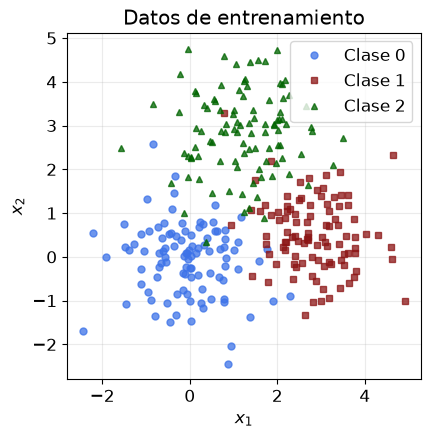

In [2]:
CENTROS = np.array([[0.0, 0.0], [3.0, 0.5], [1.2, 2.8]])
def simula(n_por_clase, rng):
    y = np.repeat(np.arange(3), n_por_clase)
    X = CENTROS[y] + rng.normal(0, 0.9, (len(y), 2))
    return X, y

X_tr, y_tr = simula(100, rng)
X_te, y_te = simula(1000, rng)
MARCAS = ["o", "s", "^"]

def dibuja(ax, X, y):
    for k in range(3):
        ax.plot(*X[y == k].T, MARCAS[k], ms=5, color=COLORES[k], alpha=0.75, label=f"Clase {k}")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")

fig, ax = plt.subplots()
dibuja(ax, X_tr, y_tr); ax.legend(); ax.set_title("Datos de entrenamiento")
plt.show()

## La función softmax

El modelo calcula un puntaje por clase, $z_k = \mathbf{x}^\top\boldsymbol\beta_k$, y los convierte en
probabilidades,
$$\Pr(y = k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}} .$$

Por ejemplo, los puntajes $(2;\ 1;\ 0{,}1)$ dan probabilidades $(0{,}66;\ 0{,}24;\ 0{,}10)$. Sumar la misma
constante a todos los puntajes no cambia el resultado, y eso permite restar el máximo antes de
exponenciar para evitar desbordes.

In [3]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)          # estabilidad numérica
    E = np.exp(Z)
    return E/E.sum(axis=1, keepdims=True)

print(softmax(np.array([[2.0, 1.0, 0.1]])).round(3))
print(softmax(np.array([[1002.0, 1001.0, 1000.1]])).round(3))   # sin restar el máximo daría inf/inf

[[0.659 0.242 0.099]]
[[0.659 0.242 0.099]]


## Entropía cruzada y gradiente

Sea $\mathbf{Y}$ la codificación one-hot de las etiquetas ($n \times K$) y $\mathbf{B} = [\boldsymbol\beta_1, \ldots, \boldsymbol\beta_K]$
la matriz de coeficientes, con una fila para el intercepto. La pérdida media con penalización L2 (sin los
interceptos) y su gradiente son
$$\ell(\mathbf{B}) = -\frac{1}{n}\sum_{i=1}^{n}\log P_{i,y_i} + \frac{\lambda}{2}\|\mathbf{B}_{\text{sin intercepto}}\|^2, \qquad
\nabla_{\mathbf{B}}\ell = \frac{1}{n}\mathbf{X}^\top(\mathbf{P} - \mathbf{Y}) + \lambda\,\mathbf{B}_{\text{sin intercepto}} .$$
El gradiente tiene la misma forma que en el caso binario: predicción menos observación, multiplicada por
la entrada.

In [4]:
def con_unos(X):
    return np.column_stack([np.ones(len(X)), X])

def one_hot(y, K):
    return np.eye(K)[y]

def perdida(B, X, y, lam=0.0):
    Z = X @ B; Z = Z - Z.max(axis=1, keepdims=True)
    lse = np.log(np.exp(Z).sum(axis=1))
    return np.mean(lse - Z[np.arange(len(y)), y]) + 0.5*lam*np.sum(B[1:]**2)

def gradiente(B, X, y, lam=0.0):
    G = X.T @ (softmax(X @ B) - one_hot(y, B.shape[1]))/len(y)
    G[1:] += lam*B[1:]
    return G

A_tr, A_te = con_unos(X_tr), con_unos(X_te)
B_prueba = rng.normal(size=(3, 3)); h = 1e-6
num = np.zeros_like(B_prueba)
for i in range(3):
    for j in range(3):
        E = np.zeros_like(B_prueba); E[i, j] = h
        num[i, j] = (perdida(B_prueba + E, A_tr, y_tr, 0.1) - perdida(B_prueba - E, A_tr, y_tr, 0.1))/(2*h)
print("Máxima diferencia con diferencias finitas:", np.max(np.abs(num - gradiente(B_prueba, A_tr, y_tr, 0.1))))

Máxima diferencia con diferencias finitas: 5.984710227391332e-10


## Descenso de gradiente

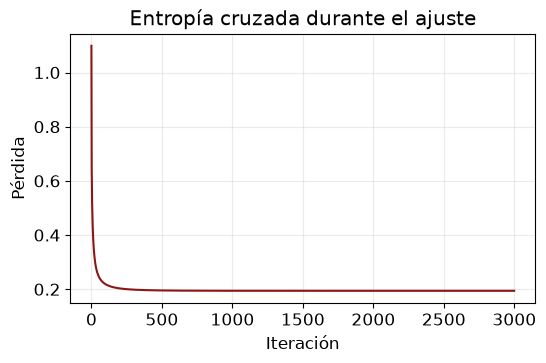

Error de entrenamiento: 0.06
Error de test:          0.09033333333333333


In [5]:
def descenso(X, y, K, lam=0.0, eta=0.5, iteraciones=3000):
    B = np.zeros((X.shape[1], K)); historia = []
    for _ in range(iteraciones):
        historia.append(perdida(B, X, y, lam))
        B = B - eta*gradiente(B, X, y, lam)
    return B, np.array(historia)

LAM = 1e-3
B, hist = descenso(A_tr, y_tr, 3, lam=LAM)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist, color=COLORES[1]); ax.set_xlabel("Iteración"); ax.set_ylabel("Pérdida"); ax.set_title("Entropía cruzada durante el ajuste")
plt.show()
print("Error de entrenamiento:", np.mean((A_tr @ B).argmax(1) != y_tr))
print("Error de test:         ", np.mean((A_te @ B).argmax(1) != y_te))

## Regiones de decisión y probabilidades

Cada punto del plano se asigna a la clase de mayor puntaje. Las fronteras entre dos clases son rectas,
porque el logaritmo del cociente de sus probabilidades, $z_k - z_j$, es lineal en $\mathbf{x}$.

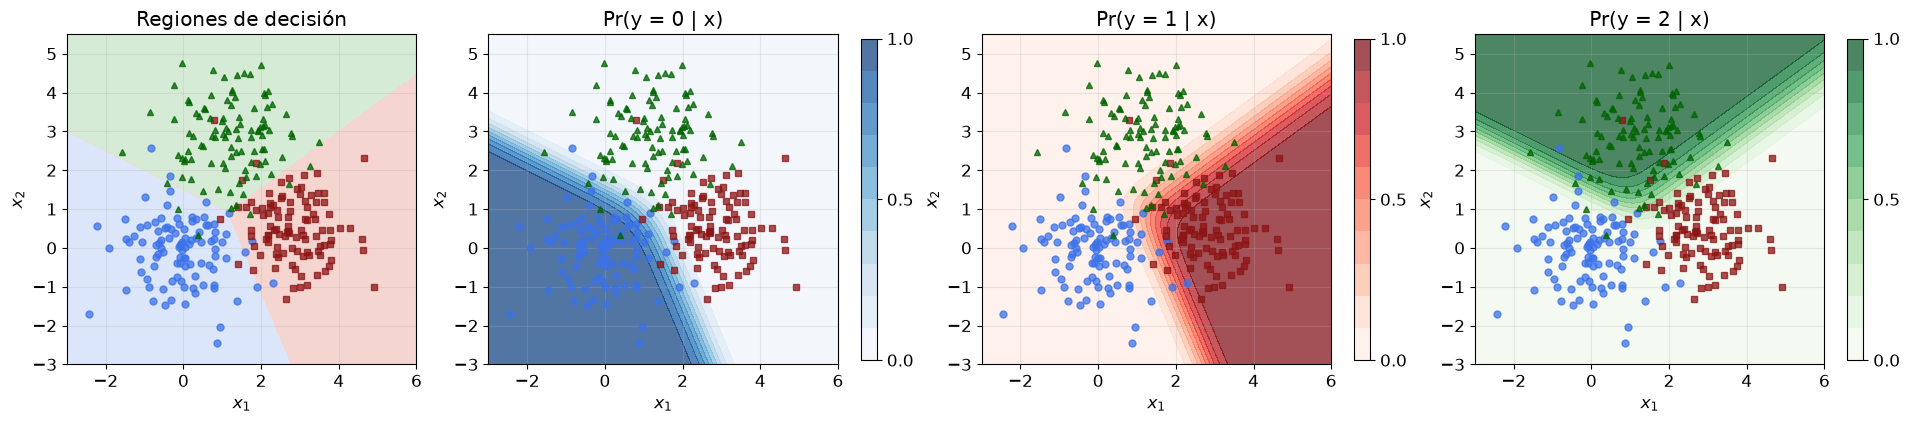

In [6]:
g1, g2 = np.meshgrid(np.linspace(-3, 6, 300), np.linspace(-3, 5.5, 300))
PG = softmax(con_unos(np.column_stack([g1.ravel(), g2.ravel()])) @ B)
fig, ax = plt.subplots(1, 4, figsize=(19, 4.4), layout="constrained")
ax[0].contourf(g1, g2, PG.argmax(1).reshape(g1.shape), levels=[-0.5, 0.5, 1.5, 2.5],
               colors=["#DCE6FA", "#F5D5D0", "#D5EBD5"])
dibuja(ax[0], X_tr, y_tr); ax[0].set_title("Regiones de decisión")
for k, cm in zip(range(3), ["Blues", "Reds", "Greens"]):
    cf = ax[k + 1].contourf(g1, g2, PG[:, k].reshape(g1.shape), levels=np.linspace(0, 1, 11), cmap=cm, alpha=0.7)
    dibuja(ax[k + 1], X_tr, y_tr); ax[k + 1].set_title(f"Pr(y = {k} | x)")
    fig.colorbar(cf, ax=ax[k + 1], fraction=0.046, ticks=[0, 0.5, 1])
plt.show()

## Dígitos manuscritos

El conjunto `load_digits` de scikit-learn tiene 1 797 imágenes de $8 \times 8$ píxeles con valores de 0 a
16. Cada imagen es un vector de 64 números, y hay diez clases. Se usan 1 000 imágenes para entrenar y el
resto para evaluar.

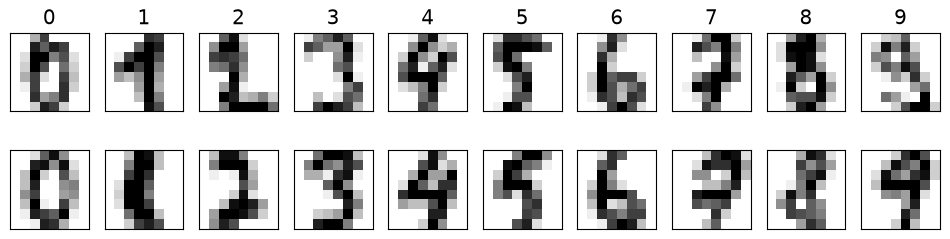

In [7]:
from sklearn.datasets import load_digits

dg = load_digits()
Xd, yd = dg.data/16.0, dg.target
perm = np.random.default_rng(0).permutation(len(yd))
itr, ite = perm[:1000], perm[1000:]
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for k in range(10):
    for f in range(2):
        ax[f, k].imshow(dg.images[itr[yd[itr] == k][f]], cmap="gray_r", interpolation="nearest")
        ax[f, k].set_xticks([]); ax[f, k].set_yticks([]); ax[f, k].grid(False)
    ax[0, k].set_title(str(k))
plt.show()

El mismo código de descenso de gradiente ajusta los $65 \times 10 = 650$ coeficientes. Con $\lambda$ pequeño la
pérdida es casi plana en algunas direcciones, y el descenso de gradiente necesita muchas iteraciones para
llegar al mínimo. Aquí se usan 20 000 pasos con $\eta = 4$, unos dos segundos.

Error de test en los dígitos: 0.03513174404015056


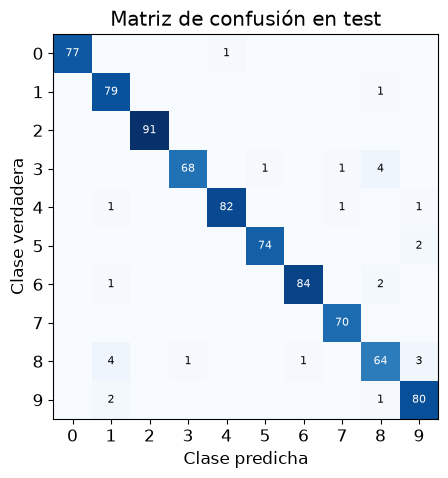

In [8]:
Ad_tr, Ad_te = con_unos(Xd[itr]), con_unos(Xd[ite])
LAM_D = 1e-3
Bd, hist_d = descenso(Ad_tr, yd[itr], 10, lam=LAM_D, eta=4.0, iteraciones=20000)
pred = (Ad_te @ Bd).argmax(1)
print("Error de test en los dígitos:", np.mean(pred != yd[ite]))

C = np.zeros((10, 10), int)
for t, p in zip(yd[ite], pred):
    C[t, p] += 1
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(C, cmap="Blues")
for i in range(10):
    for j in range(10):
        if C[i, j]:
            ax.text(j, i, C[i, j], ha="center", va="center", fontsize=8, color="w" if C[i, j] > 40 else "k")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase verdadera"); ax.set_title("Matriz de confusión en test")
plt.show()

Los pesos de cada clase se pueden ver como imágenes. Un píxel rojo aumenta el puntaje de la clase cuando
tiene tinta, y uno azul lo disminuye. Los pesos marcan los píxeles que distinguen una clase de las demás, y
por eso no se parecen al dígito promedio.

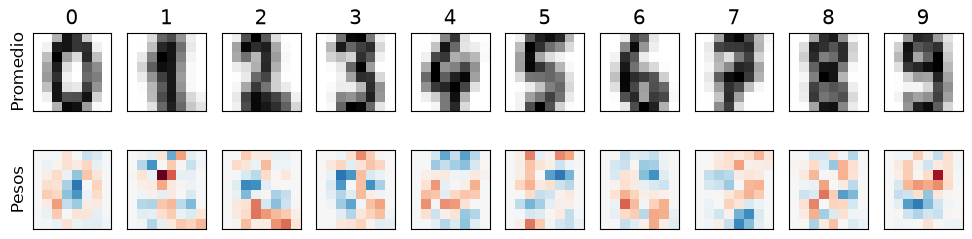

In [9]:
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
m = np.abs(Bd[1:]).max()
for k in range(10):
    ax[0, k].imshow(Xd[itr][yd[itr] == k].mean(0).reshape(8, 8), cmap="gray_r", interpolation="nearest")
    ax[1, k].imshow(Bd[1:, k].reshape(8, 8), cmap="RdBu_r", vmin=-m, vmax=m, interpolation="nearest")
    for f in range(2):
        ax[f, k].set_xticks([]); ax[f, k].set_yticks([]); ax[f, k].grid(False)
    ax[0, k].set_title(str(k))
ax[0, 0].set_ylabel("Promedio"); ax[1, 0].set_ylabel("Pesos")
plt.show()

## El mismo modelo en PyTorch

Una capa lineal de 64 entradas y 10 salidas produce los puntajes, y `CrossEntropyLoss` aplica la softmax y
la entropía cruzada en un solo paso estable. La penalización L2 se agrega a mano para no penalizar los
interceptos.

In [10]:
import torch

Xt = torch.tensor(Xd[itr], dtype=torch.float64); yt = torch.tensor(yd[itr])
capa = torch.nn.Linear(64, 10).double()
torch.nn.init.zeros_(capa.weight); torch.nn.init.zeros_(capa.bias)
opt = torch.optim.LBFGS(capa.parameters(), lr=1, max_iter=500, tolerance_grad=1e-10, tolerance_change=1e-14,
                        line_search_fn="strong_wolfe")
ce = torch.nn.CrossEntropyLoss()

def cierre():
    opt.zero_grad()
    l = ce(capa(Xt), yt) + 0.5*LAM_D*(capa.weight**2).sum()
    l.backward()
    return l

opt.step(cierre)
pred_t = capa(torch.tensor(Xd[ite], dtype=torch.float64)).argmax(1).numpy()
print("Error de test con PyTorch:", np.mean(pred_t != yd[ite]))

Error de test con PyTorch: 0.03513174404015056


## Verificación con scikit-learn

scikit-learn minimiza $C\sum_i \text{pérdida}_i + \frac{1}{2}\|\mathbf{B}\|^2$ sin penalizar los interceptos. Dividiendo por
$Cn$ se obtiene la pérdida media con $\lambda = 1/(Cn)$, de modo que $C = 1/(n\lambda)$ reproduce el modelo
de arriba. Con más clases que dos ajusta por defecto el modelo multinomial.

In [11]:
from sklearn.linear_model import LogisticRegression

sk = LogisticRegression(C=1/(len(itr)*LAM_D), tol=1e-10, max_iter=20000).fit(Xd[itr], yd[itr])
P_sk = sk.predict_proba(Xd[ite]); P_gd = softmax(Ad_te @ Bd)
print("Error de test con scikit-learn:", np.mean(sk.predict(Xd[ite]) != yd[ite]))
print("Máxima diferencia en las probabilidades (descenso de gradiente frente a scikit-learn):", np.abs(P_sk - P_gd).max())

Error de test con scikit-learn: 0.03513174404015056
Máxima diferencia en las probabilidades (descenso de gradiente frente a scikit-learn): 9.227241878906334e-07


## Ejercicios

1. Verifique que con $K = 2$ la regresión softmax da las mismas probabilidades que la regresión logística
   binaria. ¿Qué relación hay entre $\boldsymbol\beta_1 - \boldsymbol\beta_0$ y el coeficiente binario?
2. Elija $\lambda$ para los dígitos por validación cruzada de cinco pliegues, con valores entre $10^{-5}$ y $10^{-1}$.
3. Ajuste diez regresiones binarias, una por clase contra el resto, y compare su error y sus probabilidades con
   la regresión softmax.